# 04 · Product performance and price versus volume

Part A ranks categories and articles. Part B looks at how price relates to units sold within each category.

`price` is anonymized and scaled, so "revenue" here is a relative revenue score in scaled price units, not currency.

In [1]:
from dotenv import load_dotenv
import psycopg2
import pandas as pd
import os

load_dotenv(override=True)
conn = psycopg2.connect(os.getenv("SUPABASE_CONNECTION_STRING"))
cur = conn.cursor()
print("Connected successfully")

Connected successfully


## A. Category and article performance

In [2]:
cur.execute("""
    SELECT
        a.product_group_name,
        COUNT(*) AS units_sold,
        SUM(t.price) AS total_relative_revenue,
        AVG(t.price) AS avg_price
    FROM transactions t
    JOIN articles a ON t.article_id = a.article_id
    GROUP BY a.product_group_name
    ORDER BY total_relative_revenue DESC;
""")
category_perf = cur.fetchall()

category_df = pd.DataFrame(category_perf, columns=['product_group_name', 'units_sold', 'total_relative_revenue', 'avg_price'])
category_df['total_relative_revenue'] = category_df['total_relative_revenue'].astype(float)
category_df['avg_price'] = category_df['avg_price'].astype(float)

print(category_df)

       product_group_name  units_sold  total_relative_revenue  avg_price
0      Garment Upper body      740054            18897.849339   0.025536
1      Garment Lower body      441855            14157.995746   0.032042
2       Garment Full body      272229             8704.640881   0.031975
3                Swimwear      187855             3974.440254   0.021157
4               Underwear      164489             3596.260068   0.021863
5                   Shoes       44458             1482.737136   0.033351
6             Accessories       99723             1456.905695   0.014610
7                 Unknown       20882              638.958085   0.030599
8               Nightwear       17108              464.367390   0.027143
9          Socks & Tights       38232              394.675949   0.010323
10                   Bags        1238               40.758797   0.032923
11                  Items        1073               12.140119   0.011314
12  Garment and Shoe care          23              

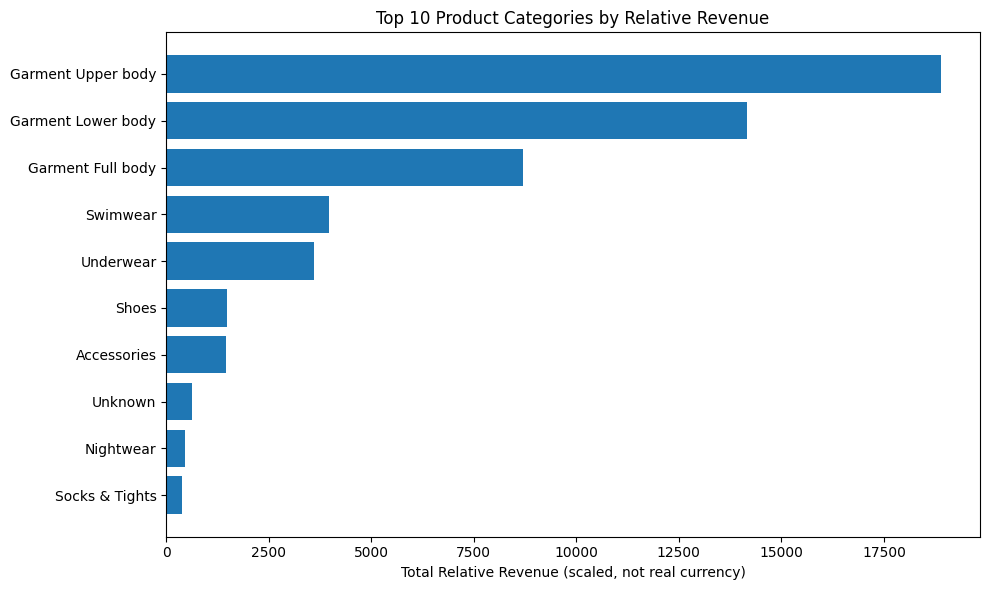

In [3]:
import matplotlib.pyplot as plt

top_categories = category_df.head(10).sort_values('total_relative_revenue')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_categories['product_group_name'], top_categories['total_relative_revenue'])
ax.set_xlabel('Total Relative Revenue (scaled, not real currency)')
ax.set_title('Top 10 Product Categories by Relative Revenue')
plt.tight_layout()
plt.savefig('../outputs/figures/category_revenue.png', dpi=150)
plt.show()

In [4]:
category_df.to_csv('../outputs/summary_tables/category_performance.csv', index=False)
print("Saved category performance")

Saved category performance


In [5]:
cur.execute("""
    SELECT
        a.product_group_name,
        t.article_id,
        a.prod_name,
        a.product_type_name,
        COUNT(*) AS units_sold,
        SUM(t.price) AS total_relative_revenue,
        AVG(t.price) AS avg_price
    FROM transactions t
    JOIN articles a ON t.article_id = a.article_id
    WHERE a.product_group_name IN ('Garment Upper body', 'Garment Lower body', 'Garment Full body')
    GROUP BY a.product_group_name, t.article_id, a.prod_name, a.product_type_name;
""")
article_detail = cur.fetchall()

article_detail_df = pd.DataFrame(
    article_detail,
    columns=['product_group_name', 'article_id', 'prod_name', 'product_type_name',
             'units_sold', 'total_relative_revenue', 'avg_price']
)
article_detail_df['total_relative_revenue'] = article_detail_df['total_relative_revenue'].astype(float)
article_detail_df['avg_price'] = article_detail_df['avg_price'].astype(float)

print(f"Articles in top 3 categories: {len(article_detail_df)}")

Articles in top 3 categories: 26894


In [6]:
best_sellers = (
    article_detail_df
    .sort_values('units_sold', ascending=False)
    .groupby('product_group_name')
    .head(5)
    .sort_values(['product_group_name', 'units_sold'], ascending=[True, False])
)

print("TOP 5 BEST SELLERS PER CATEGORY (by units)")
print(best_sellers[['product_group_name', 'prod_name', 'product_type_name', 'units_sold', 'avg_price']].to_string(index=False))

TOP 5 BEST SELLERS PER CATEGORY (by units)
product_group_name                  prod_name product_type_name  units_sold  avg_price
 Garment Full body                    Nirvana             Dress        1322   0.024931
 Garment Full body          FF PI Haley dress             Dress         917   0.032870
 Garment Full body                Riviera s/s             Dress         816   0.021698
 Garment Full body             CS Paula dress             Dress         804   0.022748
 Garment Full body                Romeo dress             Dress         800   0.029320
Garment Lower body        Pluto RW slacks (1)          Trousers        2931   0.033226
Garment Lower body   Jade HW Skinny Denim TRS          Trousers        2852   0.033175
Garment Lower body  Perrie Slim Mom Denim TRS          Trousers        2230   0.041034
Garment Lower body               Primo slacks          Trousers        1987   0.024878
Garment Lower body Victorville HW Pull-on TRS          Trousers        1880   0.024939


In [7]:
# Apply a minimum volume floor so "worst seller" is meaningful, not just a near-zero fluke
MIN_UNITS = 10
eligible = article_detail_df[article_detail_df['units_sold'] >= MIN_UNITS]

worst_sellers = (
    eligible
    .sort_values('units_sold', ascending=True)
    .groupby('product_group_name')
    .head(5)
    .sort_values(['product_group_name', 'units_sold'])
)

print(f"\nBOTTOM 5 SELLERS PER CATEGORY (min {MIN_UNITS} units, by units)")
print(worst_sellers[['product_group_name', 'prod_name', 'product_type_name', 'units_sold', 'avg_price']].to_string(index=False))
print(f"\nArticles excluded by the {MIN_UNITS}-unit threshold: {len(article_detail_df) - len(eligible)}")


BOTTOM 5 SELLERS PER CATEGORY (min 10 units, by units)
product_group_name                   prod_name product_type_name  units_sold  avg_price
 Garment Full body                         Rio             Dress          10   0.040831
 Garment Full body                 Zinia Dress             Dress          10   0.039847
 Garment Full body      ORVAR face romper 2pcs Jumpsuit/Playsuit          10   0.023995
 Garment Full body                       Katie             Dress          10   0.014698
 Garment Full body                   Dungarees Jumpsuit/Playsuit          10   0.015237
Garment Lower body        SUPREME FANCY TIGHTS          Trousers          10   0.028646
Garment Lower body           Jagger tight pant          Trousers          10   0.041508
Garment Lower body          PARTY Taylor skirt             Skirt          10   0.035161
Garment Lower body       AK Caper jsy pants HW          Trousers          10   0.021897
Garment Lower body              TIMOTHY jogger          Trousers

**Why this bottom-5 list is not a valid result.** Every item above sits at exactly 10 units, which is the threshold floor itself. The next cell shows that 454 articles are tied at 10 units across the three categories, so any "bottom 5" is an arbitrary pick from that pool, decided by row order. The project does not name individual worst sellers. The honest finding is the distribution: about half the articles in the top three categories sold fewer than 10 units in the window.

In [8]:
tie_counts = eligible[eligible['units_sold'] == 10].groupby('product_group_name').size()
print("Articles sitting at exactly 10 units, per category:")
print(tie_counts)

Articles sitting at exactly 10 units, per category:
product_group_name
Garment Full body      91
Garment Lower body    107
Garment Upper body    256
dtype: int64


In [9]:
best_sellers.to_csv('../outputs/summary_tables/best_sellers_by_category.csv', index=False)
article_detail_df.to_csv('../outputs/summary_tables/article_performance_top_categories.csv', index=False)
print("Saved article-level performance")

Saved article-level performance


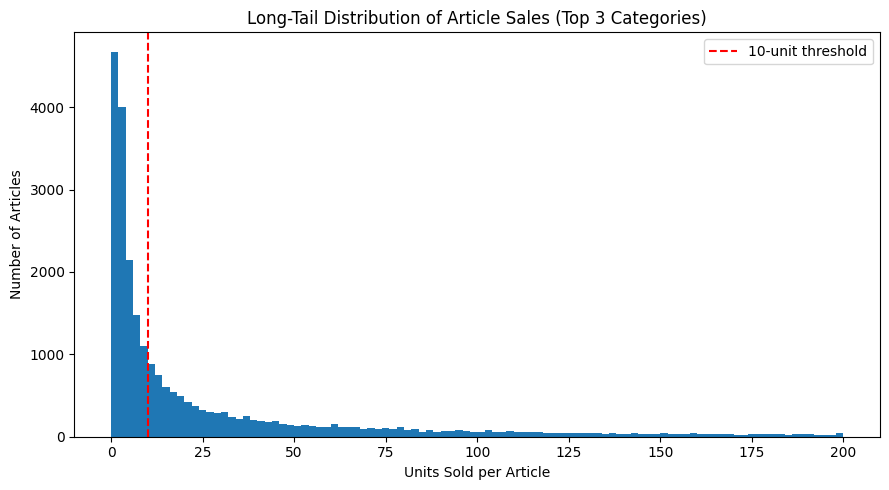

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(article_detail_df['units_sold'], bins=100, range=(0, 200))
ax.axvline(10, color='red', linestyle='--', label='10-unit threshold')
ax.set_xlabel('Units Sold per Article')
ax.set_ylabel('Number of Articles')
ax.set_title('Long-Tail Distribution of Article Sales (Top 3 Categories)')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/article_sales_distribution.png', dpi=150)
plt.show()

## B. Price sensitivity

Price sensitivity here is observational. There is no controlled price experiment, so nothing below is price elasticity or a causal claim. Articles need 10+ units, and a category needs 25+ eligible articles to form price quintiles.

In [11]:
cur.execute("""
    SELECT
        a.product_group_name,
        t.article_id,
        COUNT(*) AS units_sold,
        AVG(t.price) AS avg_price
    FROM transactions t
    JOIN articles a ON t.article_id = a.article_id
    GROUP BY a.product_group_name, t.article_id
    HAVING COUNT(*) >= 10;
""")
price_perf = cur.fetchall()

price_df = pd.DataFrame(price_perf, columns=['product_group_name', 'article_id', 'units_sold', 'avg_price'])
price_df['avg_price'] = price_df['avg_price'].astype(float)

print(f"Articles analyzed: {len(price_df)}")
print(price_df.groupby('product_group_name').size().sort_values(ascending=False))

Articles analyzed: 18990
product_group_name
Garment Upper body    6820
Garment Lower body    3881
Garment Full body     2804
Accessories           1794
Underwear             1289
Swimwear              1008
Shoes                  655
Socks & Tights         432
Nightwear              183
Unknown                 91
Bags                    17
Items                   14
Stationery               2
dtype: int64


In [12]:
def add_price_quintile(group):
    if len(group) < 25:  # need enough articles for 5 meaningful buckets
        group['price_quintile'] = pd.NA
        return group
    group['price_quintile'] = pd.qcut(
        group['avg_price'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]
    )
    return group

price_df = price_df.groupby('product_group_name', group_keys=False).apply(add_price_quintile)

quintile_summary = (
    price_df.dropna(subset=['price_quintile'])
    .groupby(['product_group_name', 'price_quintile'], observed=True)
    .agg(
        article_count=('article_id', 'count'),
        avg_units_sold=('units_sold', 'mean'),
        median_units_sold=('units_sold', 'median'),
        avg_price=('avg_price', 'mean')
    )
    .reset_index()
)

print(quintile_summary.to_string(index=False))

product_group_name price_quintile  article_count  avg_units_sold  median_units_sold  avg_price
       Accessories              1            359       55.426184               27.0   0.005614
       Accessories              2            359       48.793872               37.0   0.009244
       Accessories              3            358       52.296089               33.0   0.012627
       Accessories              4            359       49.083565               28.0   0.016149
       Accessories              5            359       54.629526               31.0   0.030810
 Garment Full body              1            561       94.377897               41.0   0.014572
 Garment Full body              2            561      108.654189               52.0   0.023445
 Garment Full body              3            560      116.396429               59.5   0.030770
 Garment Full body              4            561       92.516934               51.0   0.041373
 Garment Full body              5            561  

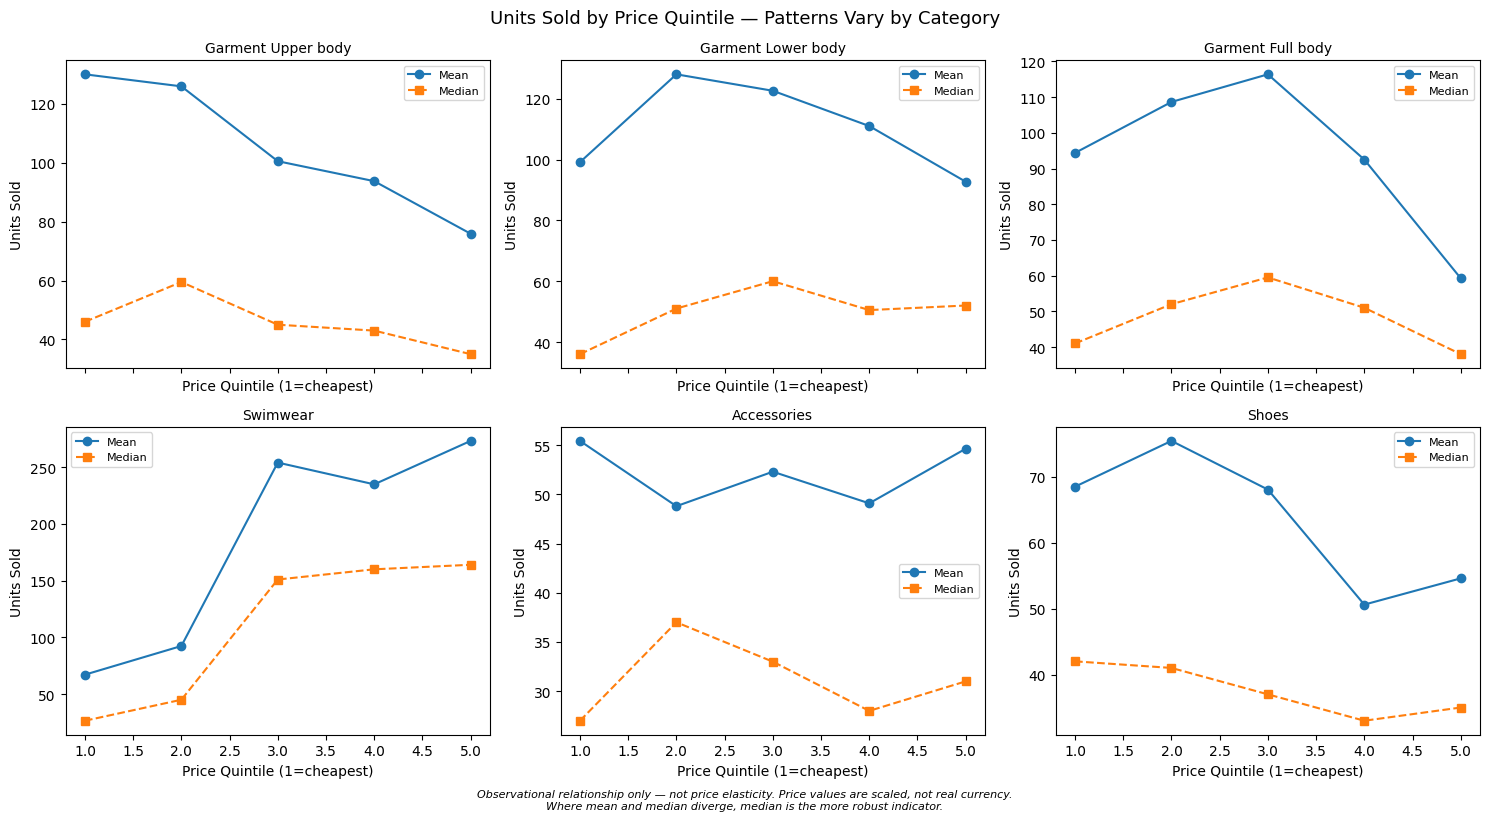

In [13]:
import matplotlib.pyplot as plt

focus_categories = ['Garment Upper body', 'Garment Lower body', 'Garment Full body',
                    'Swimwear', 'Accessories', 'Shoes']

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, cat in zip(axes.flat, focus_categories):
    sub = quintile_summary[quintile_summary['product_group_name'] == cat]
    ax.plot(sub['price_quintile'], sub['avg_units_sold'], marker='o', label='Mean')
    ax.plot(sub['price_quintile'], sub['median_units_sold'], marker='s', linestyle='--', label='Median')
    ax.set_title(cat, fontsize=10)
    ax.set_xlabel('Price Quintile (1=cheapest)')
    ax.set_ylabel('Units Sold')
    ax.legend(fontsize=8)

fig.suptitle('Units Sold by Price Quintile — Patterns Vary by Category', fontsize=13)
plt.figtext(0.5, -0.02,
            "Observational relationship only — not price elasticity. Price values are scaled, not real currency.\n"
            "Where mean and median diverge, median is the more robust indicator.",
            ha='center', fontsize=8, style='italic')
plt.tight_layout()
plt.savefig('../outputs/figures/price_quintile_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

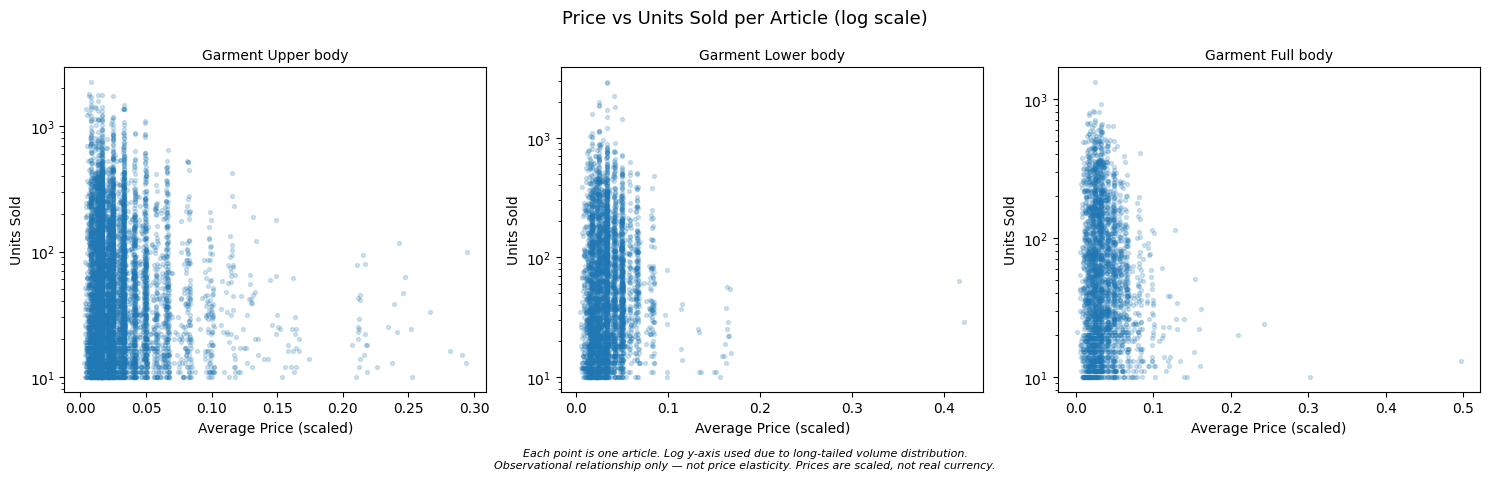

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, cat in zip(axes, ['Garment Upper body', 'Garment Lower body', 'Garment Full body']):
    sub = price_df[price_df['product_group_name'] == cat]
    ax.scatter(sub['avg_price'], sub['units_sold'], alpha=0.2, s=8)
    ax.set_title(cat, fontsize=10)
    ax.set_xlabel('Average Price (scaled)')
    ax.set_ylabel('Units Sold')
    ax.set_yscale('log')  # log scale, since volume is heavily long-tailed

fig.suptitle('Price vs Units Sold per Article (log scale)', fontsize=13)
plt.figtext(0.5, -0.04,
            "Each point is one article. Log y-axis used due to long-tailed volume distribution.\n"
            "Observational relationship only — not price elasticity. Prices are scaled, not real currency.",
            ha='center', fontsize=8, style='italic')
plt.tight_layout()
plt.savefig('../outputs/figures/price_vs_units_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
quintile_summary.to_csv('../outputs/summary_tables/price_quintile_summary.csv', index=False)
print("Saved price quintile summary")

Saved price quintile summary


## Correlation, and what it misses

Both Pearson and Spearman are reported. Spearman is the primary measure because it is rank-based and copes with the long-tailed volumes.

Garment Full body shows a clear inverted U in the quintiles above, yet its Spearman r is about -0.04. A curve that rises then falls cancels out in a correlation coefficient. So a near-zero correlation is not the same as no relationship, which is why the quintiles and scatter plots are shown alongside it.

In [16]:
from scipy.stats import pearsonr, spearmanr

results = []

for cat, sub in price_df.groupby('product_group_name'):
    if len(sub) < 25:  # same threshold as the quintile analysis
        continue
    pearson_r, pearson_p = pearsonr(sub['avg_price'], sub['units_sold'])
    spearman_r, spearman_p = spearmanr(sub['avg_price'], sub['units_sold'])
    results.append({
        'product_group_name': cat,
        'n_articles': len(sub),
        'pearson_r': round(pearson_r, 3),
        'pearson_p': round(pearson_p, 4),
        'spearman_r': round(spearman_r, 3),
        'spearman_p': round(spearman_p, 4)
    })

corr_df = pd.DataFrame(results).sort_values('spearman_r')
print(corr_df.to_string(index=False))

product_group_name  n_articles  pearson_r  pearson_p  spearman_r  spearman_p
    Socks & Tights         432      0.026     0.5893      -0.143      0.0030
Garment Upper body        6820     -0.106     0.0000      -0.075      0.0000
             Shoes         655     -0.081     0.0391      -0.062      0.1106
 Garment Full body        2804     -0.127     0.0000      -0.044      0.0196
       Accessories        1794     -0.020     0.4002      -0.013      0.5955
           Unknown          91      0.016     0.8832       0.048      0.6485
Garment Lower body        3881     -0.039     0.0162       0.071      0.0000
         Underwear        1289      0.023     0.4135       0.109      0.0001
         Nightwear         183      0.077     0.2993       0.218      0.0030
          Swimwear        1008      0.208     0.0000       0.406      0.0000


In [17]:
corr_df.to_csv('../outputs/summary_tables/price_correlation_by_category.csv', index=False)
print("Saved correlation results")

Saved correlation results
